# Team 7 · Monday: a material-finder autoencoder (MINC-2500)

**Team:** Ugo, Alvaro, Sneha · **Hackathon:** AI Methods I, 16–20 November 2026

**App idea:** a user uploads a photo of a surface (facade, floor, wall finish). The app returns the **5 most similar material patches**, a **material guess** and a warning if the photo looks **unusual** for a building material.

**Use of the autoencoder:** similarity search in latent space (main), anomaly score from the reconstruction error (bonus).

| Section | What happens |
|---|---|
| 1 | Load MINC-2500, keep 13 building materials, 64 × 64 RGB |
| 2 | Two architectures: dense AE and convolutional AE |
| 3 | Three setups on the same split and seed, one table (MSE + precision@5) |
| 4 | Similarity search: the proof figure, per-material quality, UMAP |
| 5 | Bonus: "unusual photo" score (building materials vs everything else) |
| 6 | Export for the model server: ONNX, config, gallery, examples |
| 7 | Conclusions (write them yourselves after the full run) |

**Data:** MINC-2500, Hugging Face mirror [`mcimpoi/minc-2500_split_1`](https://huggingface.co/datasets/mcimpoi/minc-2500_split_1), CC BY 4.0. Cite: Bell, Upchurch, Snavely and Bala (2015), *Material Recognition in the Wild with the Materials in Context Database*, CVPR.

**Before you run:** the parquet files must be in `data/minc-2500/data/` at the **root of the repository** (git-ignored). Download once with:

```bash
hf download mcimpoi/minc-2500_split_1 --repo-type dataset --local-dir data/minc-2500
```

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run once.
# %pip install torch torchvision polars pillow scikit-learn matplotlib umap-learn onnx onnxscript onnxruntime

In [2]:
import io
import json
import os
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import torch
from PIL import Image
from sklearn.metrics import roc_auc_score, precision_score, recall_score
from sklearn.neighbors import NearestNeighbors
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# --- Folders (relative paths: this notebook lives in 01_autoencoder/notebook/) ---
AE_DIR = Path("..")                       # 01_autoencoder/
REPO_DIR = AE_DIR / ".."                  # repository root
DATA_DIR = REPO_DIR / "data"              # git-ignored
MINC_DIR = DATA_DIR
FIG_DIR = AE_DIR / "figures"
MODEL_DIR = AE_DIR / "models"             # goes to Hugging Face (model card, ONNX, gallery)
APP_DIR = AE_DIR / "model_app"            # what the Tuesday server needs
for folder in [FIG_DIR, MODEL_DIR, APP_DIR / "examples"]:
    folder.mkdir(parents=True, exist_ok=True)

# QUICK mode: a small subset and 1 epoch, to test that the notebook runs end to end.
# For the real run leave it off (MINC_QUICK not set).
QUICK = os.environ.get("MINC_QUICK") == "1"

IMAGE_SIZE = 64
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
pd.set_option("display.float_format", "{:,.4f}".format)
print(f"PyTorch {torch.__version__}, device: {DEVICE}, QUICK mode: {QUICK}")
print("parquet files:", sorted(p.name for p in MINC_DIR.glob("*.parquet")))


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

PyTorch 2.15.0+cpu, device: cpu, QUICK mode: False
parquet files: ['test-00000-of-00001-9ca799ad09695eff.parquet', 'train-00000-of-00005-dbe3fdb3f07f1fda.parquet', 'train-00001-of-00005-5b231f26456ca063.parquet', 'train-00002-of-00005-c90a5ea07fbdddec.parquet', 'train-00004-of-00005-5a103631f553426a.parquet', 'validation-00000-of-00001-7984726e190ae40b.parquet']


# 1. The data

MINC-2500 has 23 classes of 2,500 patches each (362 × 362 px). We keep the **13 building materials** for training. The 10 other classes (food, foliage, sky, skin…) are never used for training: we only use their **test** patches in section 5, as examples of "not a building material".

**Split:** we use the train / validation / test split that comes with the dataset (split 1). The same split and seed for every setup.

**Preprocessing** (the server on Tuesday must do exactly the same, so it is one function):
1. convert to RGB;
2. centre-crop to a square (MINC patches are already square; user photos are not);
3. resize to 64 × 64 with bilinear filtering;
4. pixels 0–255 → 0–1, shape (3, 64, 64).

We keep the images as **uint8** in memory (4× less than float) and convert each batch when we use it.

In [3]:
ALL_CLASSES = ["brick", "carpet", "ceramic", "fabric", "foliage", "food", "glass", "hair", "leather",
               "metal", "mirror", "other", "painted", "paper", "plastic", "polishedstone", "skin", "sky",
               "stone", "tile", "wallpaper", "water", "wood"]          # label ids 0–22 (dataset card)
BUILDING = ["brick", "carpet", "ceramic", "glass", "metal", "mirror", "painted", "plastic",
            "polishedstone", "stone", "tile", "wallpaper", "wood"]
OTHER = [c for c in ALL_CLASSES if c not in BUILDING]
BUILDING_IDS = [ALL_CLASSES.index(c) for c in BUILDING]
OTHER_IDS = [ALL_CLASSES.index(c) for c in OTHER]
print(f"{len(BUILDING)} building materials, {len(OTHER)} other classes")


def preprocess(image: Image.Image) -> np.ndarray:
    # THE preprocessing, shared with the model server: RGB, centre square, 64 x 64, uint8 (H, W, 3)
    image = image.convert("RGB")
    w, h = image.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    image = image.crop((left, top, left + side, top + side))
    image = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.BILINEAR)
    return np.asarray(image, dtype=np.uint8)


def load_split(split, label_ids, per_class=None):
    # Read one split from the parquet files, keep some classes, decode and preprocess every image.
    files = sorted(MINC_DIR.glob(f"{split}-*.parquet"))
    assert files, f"No parquet files for '{split}' in {MINC_DIR}. Download the data first."
    df = (pl.scan_parquet(files)
          .select(pl.col("image").struct.field("bytes").alias("bytes"), pl.col("label"))
          .filter(pl.col("label").is_in(label_ids))
          .collect())
    if per_class:
        df = df.group_by("label", maintain_order=True).head(per_class)
    X = np.stack([preprocess(Image.open(io.BytesIO(b))) for b in df["bytes"]])
    return X, df["label"].to_numpy()


def load_cached(split, label_ids, name, per_class=None):
    # Decoding ~30,000 JPEGs takes a minute or two: do it once and keep a cache in data/ (git-ignored)
    cache = DATA_DIR / f"minc64_{name}{'_quick' if QUICK else ''}.npz"
    if cache.exists():
        d = np.load(cache)
        return d["X"], d["y"]
    start = time.time()
    X, y = load_split(split, label_ids, per_class)
    np.savez(cache, X=X, y=y)
    print(f"{split}/{name}: decoded {len(X):,} images in {time.time() - start:.0f} s -> {cache.name}")
    return X, y


PER_CLASS = 200 if QUICK else None          # QUICK: 200 images per class
remap = {orig: new for new, orig in enumerate(BUILDING_IDS)}   # original id -> 0..12

X_train_u8, y_train_orig = load_cached("train", BUILDING_IDS, "train", PER_CLASS)
X_val_u8, y_val_orig = load_cached("validation", BUILDING_IDS, "val", PER_CLASS and PER_CLASS // 4)
X_test_u8, y_test_orig = load_cached("test", BUILDING_IDS, "test", PER_CLASS and PER_CLASS // 4)
X_other_u8, y_other_orig = load_cached("test", OTHER_IDS, "test_other", PER_CLASS and PER_CLASS // 4)

y_train = np.array([remap[v] for v in y_train_orig])
y_val = np.array([remap[v] for v in y_val_orig])
y_test = np.array([remap[v] for v in y_test_orig])

print(f"train {X_train_u8.shape} | validation {X_val_u8.shape} | test {X_test_u8.shape} | "
      f"other-class test {X_other_u8.shape}")
pd.Series(np.bincount(y_train, minlength=len(BUILDING)), index=BUILDING, name="train patches").to_frame().T

13 building materials, 10 other classes
train (22525, 64, 64, 3) | validation (1625, 64, 64, 3) | test (3250, 64, 64, 3) | other-class test (2500, 64, 64, 3)


,brick,carpet,ceramic,glass,metal,mirror,painted,plastic,polishedstone,stone,tile,wallpaper,wood
train patches,2125,2125,2125,2125,2125,2125,2125,0,0,1275,2125,2125,2125


Figure saved to ..\figures\01_samples.png


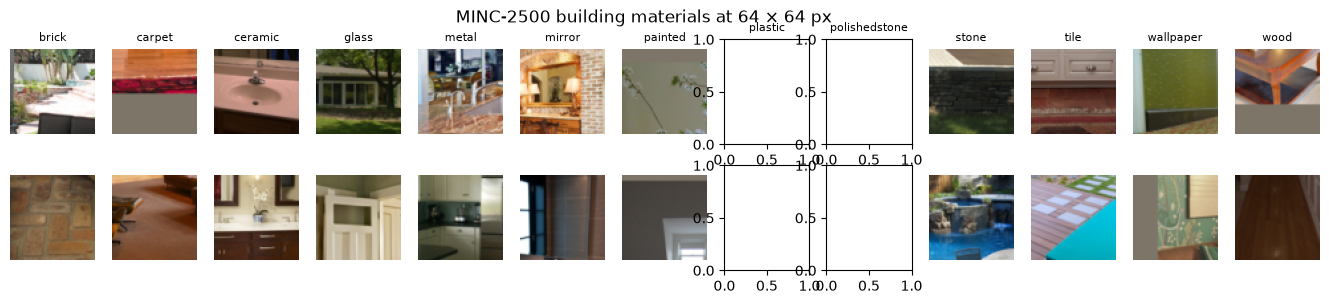

In [4]:
# Two example patches per building material, as the model sees them (64 x 64)
fig, axes = plt.subplots(2, len(BUILDING), figsize=(len(BUILDING) * 1.3, 3))
for k, name in enumerate(BUILDING):
    idx = np.flatnonzero(y_train == k)[:2]
    for row, i in enumerate(idx):
        axes[row, k].imshow(X_train_u8[i])
        axes[row, k].axis("off")
    axes[0, k].set_title(name, fontsize=8)
plt.suptitle("MINC-2500 building materials at 64 × 64 px")
save_fig("01_samples")
plt.show()

In [5]:
# uint8 (N, H, W, 3) -> torch uint8 (N, 3, H, W). Batches become floats 0-1 only when used.
def to_tensor(X_u8):
    return torch.from_numpy(X_u8).permute(0, 3, 1, 2).contiguous()


def to_float(batch_u8):
    return batch_u8.float().div(255)


X_train = to_tensor(X_train_u8)
X_val = to_tensor(X_val_u8)
X_test = to_tensor(X_test_u8)
X_other = to_tensor(X_other_u8)
print(X_train.shape, X_train.dtype)

torch.Size([22525, 3, 64, 64]) torch.uint8


# 2. Two architectures

- **DenseAE:** flattens the 64 × 64 × 3 = 12,288 numbers and squeezes them through a hidden layer of 256 to the code. It ignores that neighbouring pixels belong together: our baseline.
- **ConvAE:** three stride-2 convolutions halve the image 64 → 32 → 16 → 8, then a linear layer makes the code. The decoder mirrors it with transposed convolutions. A `Sigmoid` at the end keeps the output pixels in 0–1.

Both have an `encoder` (image → code) and a `decoder` (code → image). The **code** (latent vector) is what we use for similarity search.

In [6]:
class DenseAE(nn.Module):
    def __init__(self, latent_dim=64, hidden=256):
        super().__init__()
        n = 3 * IMAGE_SIZE * IMAGE_SIZE
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(n, hidden), nn.ReLU(), nn.Linear(hidden, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden), nn.ReLU(), nn.Linear(hidden, n), nn.Sigmoid(),
                                     nn.Unflatten(1, (3, IMAGE_SIZE, IMAGE_SIZE)))

    def forward(self, x):
        return self.decoder(self.encoder(x))


class ConvAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.latent_dim = latent_dim
        s = IMAGE_SIZE // 8                                                   # 64 -> 8
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1), nn.ReLU(),            # 64 -> 32
            nn.Conv2d(32, 64, 4, stride=2, padding=1), nn.ReLU(),           # 32 -> 16
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.ReLU(),          # 16 -> 8
            nn.Flatten(),
            nn.Linear(128 * s * s, latent_dim),                              # the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * s * s), nn.ReLU(),
            nn.Unflatten(1, (128, s, s)),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.ReLU(),  # 8 -> 16
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),   # 16 -> 32
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1), nn.Sigmoid(), # 32 -> 64
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


def n_params(model):
    return sum(p.numel() for p in model.parameters())


for m in [DenseAE(64), ConvAE(32), ConvAE(128)]:
    out = m(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE))
    print(f"{type(m).__name__:8s} latent {m.latent_dim:4d}: {n_params(m):>10,} parameters, output {tuple(out.shape)}")

DenseAE  latent   64:  6,337,088 parameters, output (2, 3, 64, 64)
ConvAE   latent   32:    863,587 parameters, output (2, 3, 64, 64)
ConvAE   latent  128:  2,436,547 parameters, output (2, 3, 64, 64)


In [7]:
def train_autoencoder(model, X_train, X_val, epochs=12, lr=1e-3, batch_size=128, verbose=True):
    # Train an autoencoder to rebuild its input (MSE). X_* are uint8 tensors (N, 3, H, W).
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(RANDOM_STATE))
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for (batch,) in loader:
            x = to_float(batch).to(DEVICE)
            loss = nn.functional.mse_loss(model(x), x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
        val_mse = reconstruction_error(model, X_val).mean().item()
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_mse": val_mse})
        if verbose:
            print(f"epoch {epoch:2d}  train loss {total / len(X_train):.5f}  validation MSE {val_mse:.5f}")
    seconds = time.time() - start
    print(f"trained in {seconds:.0f} s")
    return model, pd.DataFrame(history), seconds


@torch.no_grad()
def reconstruction_error(model, X, batch_size=500):
    # One number per image: mean squared difference between input and output
    model.eval()
    errors = []
    for i in range(0, len(X), batch_size):
        x = to_float(X[i:i + batch_size]).to(DEVICE)
        errors.append(((model(x) - x) ** 2).mean(dim=(1, 2, 3)).cpu())
    return torch.cat(errors)


@torch.no_grad()
def reconstruct(model, X, batch_size=500):
    model.eval()
    return torch.cat([model(to_float(X[i:i + batch_size]).to(DEVICE)).cpu() for i in range(0, len(X), batch_size)])


@torch.no_grad()
def encode(model, X, batch_size=500):
    # Images -> latent codes (numpy, N x latent_dim)
    model.eval()
    return torch.cat([model.encoder(to_float(X[i:i + batch_size]).to(DEVICE)).cpu()
                      for i in range(0, len(X), batch_size)]).numpy()


def precision_at_k(Z_gallery, y_gallery, Z_query, y_query, k=5):
    # Share of the k nearest gallery codes that have the same material as the query.
    # The AE never saw the labels: this measures whether its latent space groups materials.
    nn_index = NearestNeighbors(n_neighbors=k).fit(Z_gallery)
    _, idx = nn_index.kneighbors(Z_query)
    hits = y_gallery[idx] == y_query[:, None]
    return hits.mean(), hits.mean(axis=1)

# 3. Three setups, one table

All setups use the same split, seed, number of epochs and learning rate.

| Setup | Question it answers |
|---|---|
| Dense AE, latent 64 | Baseline: what do we lose without convolutions? |
| Conv AE, latent 32 | Is a small, fast code good enough? |
| Conv AE, latent 128 | Does a bigger code rebuild better **and** find better neighbours? |

Columns: parameters, training time, validation and test MSE, and **precision@5**: for each test patch, the share of its 5 nearest **training** patches (in latent space) with the same material. Random guessing gives 1/13 ≈ 0.077.

⏱️ On a laptop CPU the full run takes a while (the conv models are the slow part). With a GPU or Apple MPS it is much faster.

In [8]:
EPOCHS = 1 if QUICK else 12
SETUPS = [
    ("dense AE, latent 64", lambda: DenseAE(latent_dim=64)),
    ("conv AE, latent 32", lambda: ConvAE(latent_dim=32)),
    ("conv AE, latent 128", lambda: ConvAE(latent_dim=128)),
]

models, histories, rows = {}, {}, []
for name, make in SETUPS:
    print(f"\n=== {name} ===")
    model, history, seconds = train_autoencoder(make(), X_train, X_val, epochs=EPOCHS)
    Z_tr, Z_te = encode(model, X_train), encode(model, X_test)
    p5, _ = precision_at_k(Z_tr, y_train, Z_te, y_test, k=5)
    models[name], histories[name] = model, history
    rows.append({
        "setup": name,
        "parameters": n_params(model),
        "train time (s)": round(seconds),
        "val MSE": reconstruction_error(model, X_val).mean().item(),
        "test MSE": reconstruction_error(model, X_test).mean().item(),
        "precision@5": p5,
    })

results = pd.DataFrame(rows).set_index("setup")
results.to_csv(AE_DIR / "results_table.csv")
results


=== dense AE, latent 64 ===
epoch  1  train loss 0.03382  validation MSE 0.02249
epoch  2  train loss 0.01906  validation MSE 0.01885
epoch  3  train loss 0.01692  validation MSE 0.01714
epoch  4  train loss 0.01612  validation MSE 0.01712
epoch  5  train loss 0.01588  validation MSE 0.01658
epoch  6  train loss 0.01556  validation MSE 0.01662
epoch  7  train loss 0.01550  validation MSE 0.01641
epoch  8  train loss 0.01545  validation MSE 0.01658
epoch  9  train loss 0.01543  validation MSE 0.01649
epoch 10  train loss 0.01538  validation MSE 0.01635
epoch 11  train loss 0.01537  validation MSE 0.01639
epoch 12  train loss 0.01537  validation MSE 0.01647
trained in 256 s

=== conv AE, latent 32 ===
epoch  1  train loss 0.03646  validation MSE 0.01977
epoch  2  train loss 0.01477  validation MSE 0.01379
epoch  3  train loss 0.01226  validation MSE 0.01210
epoch  4  train loss 0.01099  validation MSE 0.01126
epoch  5  train loss 0.01047  validation MSE 0.01093
epoch  6  train loss 0.01

,parameters,train time (s),val MSE,test MSE,precision@5
setup,,,,,
"dense AE, latent 64",6337088,256,0.0165,0.0162,0.1340
"conv AE, latent 32",863587,950,0.0104,0.0104,0.1357
"conv AE, latent 128",2436547,1137,0.0054,0.0054,0.1282


Figure saved to ..\figures\02_training_curves.png


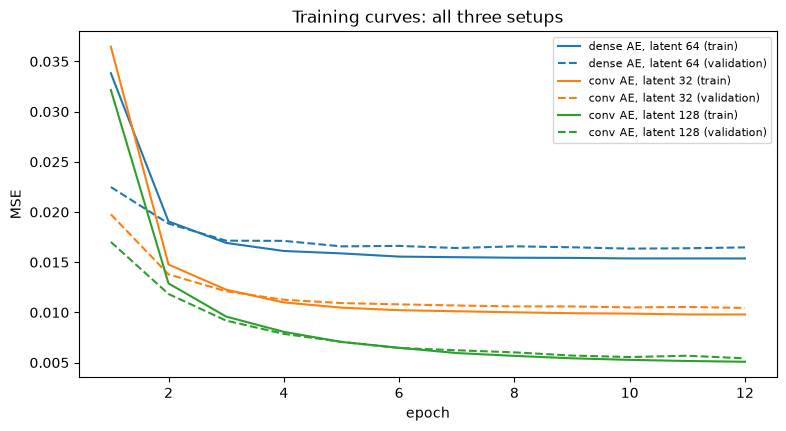

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, h in histories.items():
    line, = ax.plot(h["epoch"], h["train_loss"], label=f"{name} (train)")
    ax.plot(h["epoch"], h["val_mse"], "--", color=line.get_color(), label=f"{name} (validation)")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.set_title("Training curves: all three setups")
ax.legend(fontsize=8)
save_fig("02_training_curves")
plt.show()

chosen setup: conv AE, latent 32
Figure saved to ..\figures\03_reconstructions.png


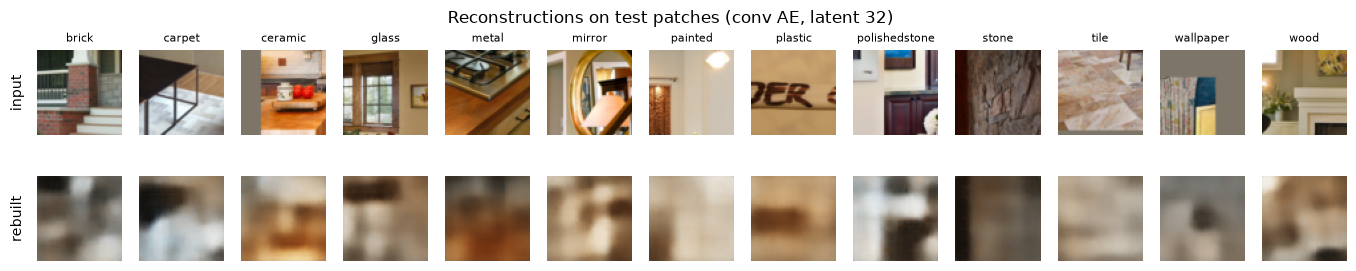

In [10]:
# Which setup goes to the app? The app's job is similarity search, so we pick the best precision@5.
BEST = results["precision@5"].idxmax()
model = models[BEST].to(DEVICE)
print("chosen setup:", BEST)

idx = np.concatenate([np.flatnonzero(y_test == k)[:1] for k in range(len(BUILDING))])
rebuilt = reconstruct(model, X_test[idx])
fig, axes = plt.subplots(2, len(idx), figsize=(len(idx) * 1.3, 3))
for j, i in enumerate(idx):
    axes[0, j].imshow(X_test_u8[i]); axes[0, j].set_title(BUILDING[y_test[i]], fontsize=8)
    axes[1, j].imshow(rebuilt[j].permute(1, 2, 0).numpy())
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].text(-10, 32, "input", rotation=90, va="center", ha="right")
axes[1, 0].text(-10, 32, "rebuilt", rotation=90, va="center", ha="right")
plt.suptitle(f"Reconstructions on test patches ({BEST})")
save_fig("03_reconstructions")
plt.show()

**✍️ Your conclusion on the table (write it after the full run, not before):**
- Which setup rebuilds best (MSE)? Which finds the best neighbours (precision@5)? Is it the same one?
- How much better than random (0.077) is precision@5?
- What do the reconstructions keep (colour, brightness, coarse texture) and what do they lose (fine detail)?
- Was the extra cost (parameters, time) of the bigger model worth it?

# 4. Similarity search: does "find similar" work?

This is the engine of the app: encode a collection once, store the codes, and for a new photo compute its code and return the closest stored ones.

**Proof figure:** a query test patch, then its 5 nearest training patches with their material and distance.

Figure saved to ..\figures\04_similarity_search.png


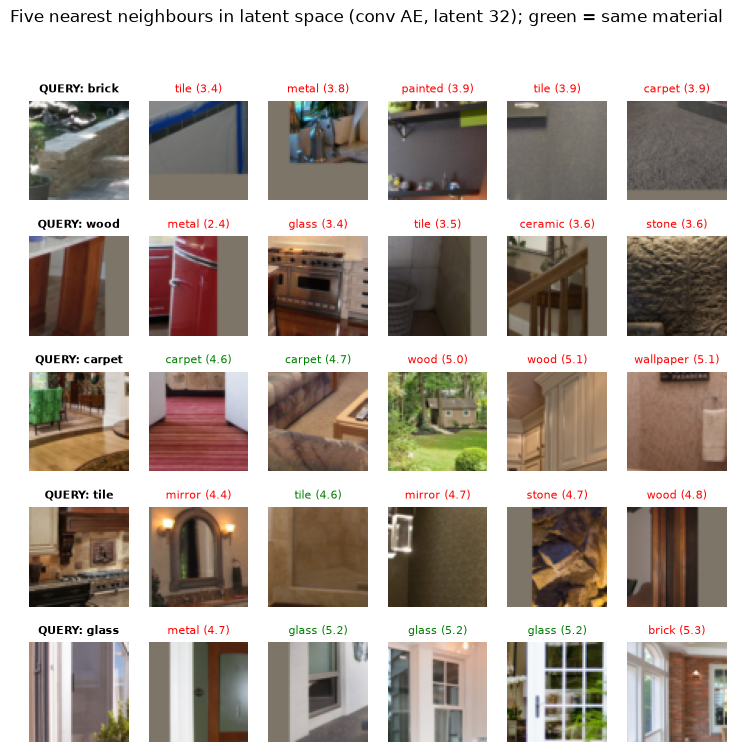

median distance to the 5 neighbours: 4.65 | between two random patches: 8.31


In [11]:
Z_train = encode(model, X_train)
Z_test = encode(model, X_test)
index = NearestNeighbors(n_neighbors=5).fit(Z_train)

SHOW = ["brick", "wood", "carpet", "tile", "glass"]
queries = [int(np.flatnonzero(y_test == BUILDING.index(m))[3]) for m in SHOW]
dist, nbr = index.kneighbors(Z_test[queries])

fig, axes = plt.subplots(len(SHOW), 6, figsize=(9, 1.7 * len(SHOW)))
for r, q in enumerate(queries):
    axes[r, 0].imshow(X_test_u8[q]); axes[r, 0].set_title(f"QUERY: {BUILDING[y_test[q]]}", fontsize=8, fontweight="bold")
    for c in range(5):
        i = nbr[r, c]
        same = y_train[i] == y_test[q]
        axes[r, c + 1].imshow(X_train_u8[i])
        axes[r, c + 1].set_title(f"{BUILDING[y_train[i]]} ({dist[r, c]:.1f})", fontsize=8,
                                 color="green" if same else "red")
    for a in axes[r]:
        a.axis("off")
plt.suptitle(f"Five nearest neighbours in latent space ({BEST}); green = same material")
save_fig("04_similarity_search")
plt.show()

random_pairs = rng.integers(0, len(Z_train), size=(2000, 2))
median_random = np.median(np.linalg.norm(Z_train[random_pairs[:, 0]] - Z_train[random_pairs[:, 1]], axis=1))
print(f"median distance to the 5 neighbours: {np.median(dist):.2f} | between two random patches: {median_random:.2f}")

Figure saved to ..\figures\05_precision_per_material.png


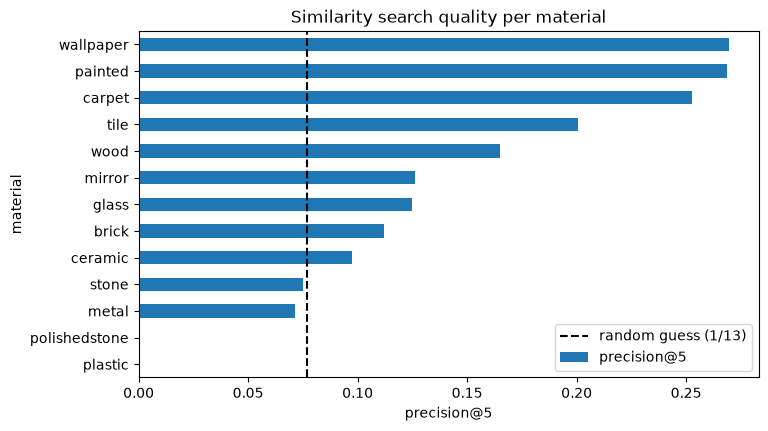

material,plastic,polishedstone,metal,stone,ceramic,brick,glass,mirror,wood,tile,carpet,painted,wallpaper
precision@5,0.0000,0.0000,0.0712,0.0752,0.0976,0.1120,0.1248,0.1264,0.1648,0.2008,0.2528,0.2688,0.2696


In [12]:
# Which materials does the latent space recognise, and which does it confuse?
_, per_query = precision_at_k(Z_train, y_train, Z_test, y_test, k=5)
per_material = (pd.DataFrame({"material": [BUILDING[k] for k in y_test], "precision@5": per_query})
                .groupby("material")["precision@5"].mean().sort_values())

fig, ax = plt.subplots(figsize=(8, 4.5))
per_material.plot.barh(ax=ax, color="tab:blue")
ax.axvline(1 / len(BUILDING), color="black", linestyle="--", label="random guess (1/13)")
ax.set_xlabel("precision@5"); ax.set_title("Similarity search quality per material"); ax.legend()
save_fig("05_precision_per_material")
plt.show()
per_material.to_frame().T

In [13]:
# A 2D map of the latent space (UMAP), coloured by material. The colours are NOT used by the model.
try:
    import umap
    sub = rng.choice(len(Z_test), size=min(3000, len(Z_test)), replace=False)
    xy = umap.UMAP(random_state=RANDOM_STATE).fit_transform(Z_test[sub])
    fig, ax = plt.subplots(figsize=(9, 7))
    cmap = plt.get_cmap("tab20")
    for k, name in enumerate(BUILDING):
        m = y_test[sub] == k
        ax.scatter(xy[m, 0], xy[m, 1], s=5, color=cmap(k), label=name)
    ax.legend(markerscale=4, fontsize=8, ncol=2); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"UMAP of the latent space of test patches ({BEST})")
    save_fig("06_latent_umap")
    plt.show()
except ImportError:
    print("umap-learn is not installed: skip this figure (pip install umap-learn)")

umap-learn is not installed: skip this figure (pip install umap-learn)


# 5. Bonus: an "unusual photo" score

The app should warn when a photo is not a building-material surface at all (a face, a plate of food, the sky). The autoencoder was trained only on building materials, so it should rebuild those better than anything else.

1. The **threshold** is the 95th percentile of the reconstruction error on **validation** building patches: about 5% false alarms by design.
2. We test it **once** on test patches: building materials (normal) vs the 10 other MINC classes (unusual), which the model never saw.

threshold 0.02378
ROC AUC   0.647  (0.5 = no better than chance)
precision 0.605  recall 0.110
Figure saved to ..\figures\07_unusual_histogram.png


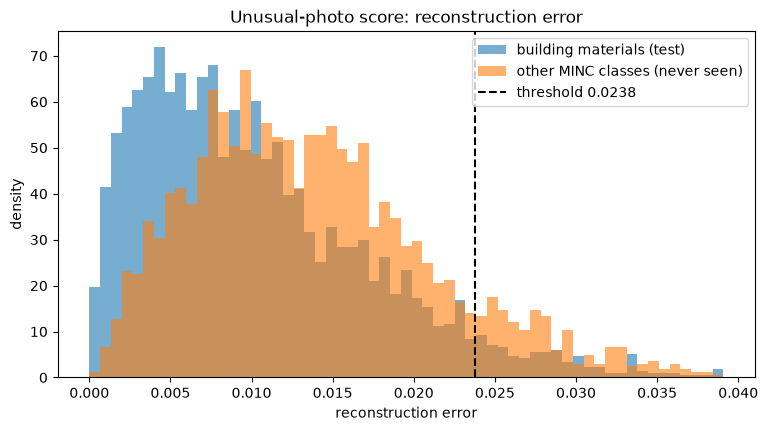

,mean_error,flagged
class,,
sky,0.0098,0.0160
fabric,0.0123,0.0880
hair,0.0124,0.0760
leather,0.0128,0.0840
skin,0.0142,0.1240
water,0.0147,0.1160
foliage,0.0147,0.1080
other,0.0153,0.1360
paper,0.0157,0.2000


In [14]:
val_errors = reconstruction_error(model, X_val).numpy()
THRESHOLD = float(np.quantile(val_errors, 0.95))

err_building = reconstruction_error(model, X_test).numpy()
err_other = reconstruction_error(model, X_other).numpy()
scores = np.concatenate([err_building, err_other])
is_unusual = np.concatenate([np.zeros(len(err_building)), np.ones(len(err_other))]).astype(int)
flagged = (scores > THRESHOLD).astype(int)

UNUSUAL_AUC = roc_auc_score(is_unusual, scores)
print(f"threshold {THRESHOLD:.5f}")
print(f"ROC AUC   {UNUSUAL_AUC:.3f}  (0.5 = no better than chance)")
print(f"precision {precision_score(is_unusual, flagged):.3f}  recall {recall_score(is_unusual, flagged):.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(0, np.quantile(scores, 0.995), 60)
ax.hist(err_building, bins=bins, alpha=0.6, density=True, label="building materials (test)")
ax.hist(err_other, bins=bins, alpha=0.6, density=True, label="other MINC classes (never seen)")
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"threshold {THRESHOLD:.4f}")
ax.set_xlabel("reconstruction error"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Unusual-photo score: reconstruction error")
save_fig("07_unusual_histogram")
plt.show()

other_names = [ALL_CLASSES[v] for v in y_other_orig]
(pd.DataFrame({"class": other_names, "error": err_other, "flagged": flagged[len(err_building):]})
   .groupby("class").agg(mean_error=("error", "mean"), flagged=("flagged", "mean")).sort_values("mean_error"))

**✍️ Interpret honestly:** reconstruction error measures *how hard a picture is to rebuild*, not *what it is*. Smooth classes (sky, water) may be rebuilt **easily** and slip through; busy textures (foliage, hair) stand out. If the ROC AUC is low, say so: in the app, show the score as a hint, not a verdict.

# 6. Export for the model server (Tuesday)

The server needs:

| File | Where | What |
|---|---|---|
| `material_ae.onnx` | `models/` and `model_app/` | image → **(reconstruction, code)** in one call |
| `config.json` | `models/` and `model_app/` | preprocessing, sizes, classes, threshold, results |
| `gallery_latents.npy` | `models/` | codes of the gallery patches (what we search in) |
| `gallery_meta.json` | `models/` | id and material of each gallery patch |
| `gallery_thumbs/*.jpg` | `models/` | the 64 px thumbnails the app shows |
| `examples/*.jpg` | `model_app/` | a few test photos for the server page |

`models/` goes to Hugging Face. `*.onnx` and `*.npy` are git-ignored, so the Render server **downloads them from Hugging Face** at startup.

In [15]:
%pip install onnx onnxscript

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [16]:
class MaterialAE(nn.Module):
    # Wrapper for export: one call returns the reconstruction and the code
    def __init__(self, ae):
        super().__init__()
        self.ae = ae

    def forward(self, image):
        code = self.ae.encoder(image)
        return self.ae.decoder(code), code


export_model = MaterialAE(models[BEST].cpu().eval()).eval()
example_input = to_float(X_test[:1])
onnx_path = MODEL_DIR / "material_ae.onnx"
torch.onnx.export(export_model, (example_input,), onnx_path,
                  input_names=["image"], output_names=["reconstruction", "code"],
                  dynamic_axes={"image": {0: "batch"}}, dynamo=False)
shutil.copy(onnx_path, APP_DIR / "material_ae.onnx")
torch.save(models[BEST].state_dict(), MODEL_DIR / "material_ae.pt")
print(f"{onnx_path}: {onnx_path.stat().st_size / 1e6:.1f} MB")

C:\Users\ugome\AppData\Local\Temp\ipykernel_13628\7991398.py:15: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(export_model, (example_input,), onnx_path,


..\models\material_ae.onnx: 3.5 MB


In [17]:
counts = np.bincount(y_train, minlength=len(BUILDING))
for k, name in enumerate(BUILDING):
    print(k, name, counts[k])
print("QUICK mode:", QUICK, "| train size:", len(y_train))

0 brick 2125
1 carpet 2125
2 ceramic 2125
3 glass 2125
4 metal 2125
5 mirror 2125
6 painted 2125
7 plastic 0
8 polishedstone 0
9 stone 1275
10 tile 2125
11 wallpaper 2125
12 wood 2125
QUICK mode: False | train size: 22525


In [18]:
counts = np.bincount(y_train, minlength=len(BUILDING))
for k, name in enumerate(BUILDING):
    print(k, name, counts[k])
print("QUICK:", QUICK, "| train size:", len(y_train), "| labels present:", np.unique(y_train))

0 brick 2125
1 carpet 2125
2 ceramic 2125
3 glass 2125
4 metal 2125
5 mirror 2125
6 painted 2125
7 plastic 0
8 polishedstone 0
9 stone 1275
10 tile 2125
11 wallpaper 2125
12 wood 2125
QUICK: False | train size: 22525 | labels present: [ 0  1  2  3  4  5  6  9 10 11 12]


In [19]:
# The gallery: a balanced sample of training patches the app searches in
GALLERY_PER_CLASS = 20 if QUICK else 300
empty = [BUILDING[k] for k in range(len(BUILDING)) if not (y_train == k).any()]
print("Classes with no training images:", empty)
gallery_idx = np.concatenate([
    rng.choice(np.flatnonzero(y_train == k),
               size=min(GALLERY_PER_CLASS, int((y_train == k).sum())),
               replace=False)
    for k in range(len(BUILDING)) if (y_train == k).any()
])
Z_gallery = encode(models[BEST].to(DEVICE), X_train[gallery_idx]).astype(np.float32)
np.save(MODEL_DIR / "gallery_latents.npy", Z_gallery)

thumb_dir = MODEL_DIR / "gallery_thumbs"
thumb_dir.mkdir(exist_ok=True)
meta = []
for gid, i in enumerate(gallery_idx):
    Image.fromarray(X_train_u8[i]).save(thumb_dir / f"{gid:05d}.jpg", quality=90)
    meta.append({"id": gid, "material": BUILDING[y_train[i]], "thumb": f"gallery_thumbs/{gid:05d}.jpg"})
(MODEL_DIR / "gallery_meta.json").write_text(json.dumps(meta))

# How good is search in this smaller gallery (the one the app really uses)?
p5_gallery, _ = precision_at_k(Z_gallery, y_train[gallery_idx], encode(model, X_test), y_test)
print(f"gallery: {len(gallery_idx):,} patches, codes {Z_gallery.shape}, precision@5 in this gallery: {p5_gallery:.3f}")

Classes with no training images: ['plastic', 'polishedstone']
gallery: 3,300 patches, codes (3300, 32), precision@5 in this gallery: 0.123


In [20]:
config = {
    "model": "material_ae.onnx",
    "setup": BEST,
    "latent_dim": int(models[BEST].latent_dim),
    "image_size": IMAGE_SIZE,
    "preprocessing": "RGB, centre-crop to a square, resize to 64x64 (PIL bilinear), pixels / 255 -> 0-1, "
                     "shape (1, 3, 64, 64) float32",
    "inputs": {"image": "float32 (batch, 3, 64, 64), values 0-1"},
    "outputs": {"reconstruction": "float32 (batch, 3, 64, 64)", "code": "float32 (batch, latent_dim)"},
    "classes": BUILDING,
    "similarity": "Euclidean distance between codes; top 5 gallery patches; material guess = majority vote",
    "gallery_size": int(len(gallery_idx)),
    "unusual_threshold": THRESHOLD,
    "unusual_threshold_rule": "95th percentile of the reconstruction error on validation building patches",
    "results": {
        "test_mse": float(results.loc[BEST, "test MSE"]),
        "precision_at_5_full_train": float(results.loc[BEST, "precision@5"]),
        "precision_at_5_gallery": float(p5_gallery),
        "unusual_roc_auc": float(UNUSUAL_AUC),
    },
    "dataset": "MINC-2500 (mcimpoi/minc-2500_split_1), CC BY 4.0, Bell et al. 2015 CVPR",
    "quick_mode": QUICK,
}
for folder in [MODEL_DIR, APP_DIR]:
    (folder / "config.json").write_text(json.dumps(config, indent=2))

# Example inputs for the server page: original 362 px test patches (not our 64 px copies)
test_files = sorted(MINC_DIR.glob("test-*.parquet"))
for name in ["brick", "wood", "tile", "carpet"]:
    row = (pl.scan_parquet(test_files).filter(pl.col("label") == ALL_CLASSES.index(name))
           .select(pl.col("image").struct.field("bytes")).head(1).collect())
    Image.open(io.BytesIO(row.item())).convert("RGB").save(APP_DIR / "examples" / f"{name}.jpg", quality=92)

# The model card on Hugging Face needs the figures next to it
shutil.copytree(FIG_DIR, MODEL_DIR / "figures", dirs_exist_ok=True)
for p in sorted(APP_DIR.rglob("*.*")):
    print(f"{str(p):45s} {p.stat().st_size / 1024:9.1f} KB")

..\model_app\config.json                            1.2 KB
..\model_app\examples\brick.jpg                    29.1 KB
..\model_app\examples\carpet.jpg                   33.5 KB
..\model_app\examples\tile.jpg                     28.9 KB
..\model_app\examples\wood.jpg                     27.0 KB
..\model_app\material_ae.onnx                    3378.9 KB


In [21]:
%pip install onnxruntime

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [22]:
# Check: ONNX Runtime gives the same codes and reconstructions as PyTorch,
# and the full path (photo file -> preprocess -> ONNX -> nearest gallery patches) works like the server will.
import onnxruntime as ort

session = ort.InferenceSession(str(APP_DIR / "material_ae.onnx"))
batch = to_float(X_test[:5])
onnx_rec, onnx_code = session.run(None, {"image": batch.numpy()})
with torch.no_grad():
    torch_rec, torch_code = export_model(batch)
print("same codes:          ", np.allclose(onnx_code, torch_code.numpy(), atol=1e-4))
print("same reconstructions:", np.allclose(onnx_rec, torch_rec.numpy(), atol=1e-4))

# What the server will do with an uploaded photo
photo = Image.open(APP_DIR / "examples" / "brick.jpg")
x = preprocess(photo).astype(np.float32).transpose(2, 0, 1)[None] / 255.0
rec, code_ = session.run(None, {"image": x})
d = np.linalg.norm(Z_gallery - code_, axis=1)
top = np.argsort(d)[:5]
votes = pd.Series([meta[i]["material"] for i in top]).value_counts()
print(f"brick.jpg -> guess '{votes.index[0]}' ({votes.iloc[0]}/5), unusual score "
      f"{float(((rec - x) ** 2).mean()):.5f} (threshold {THRESHOLD:.5f})")
print("top 5:", [(meta[i]["material"], round(float(d[i]), 2)) for i in top])

same codes:           True
same reconstructions: True
brick.jpg -> guess 'wood' (1/5), unusual score 0.01657 (threshold 0.02378)
top 5: [('wood', 4.81), ('carpet', 5.04), ('ceramic', 5.14), ('wallpaper', 5.18), ('glass', 5.2)]


#### CHANGES BELOW

In [23]:
%pip install opencv-python scikit-image

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 1.1 MB/s eta 0:00:39
   ---------------------------------------- 0.5/44.0 MB 1.1 MB/s eta 0:00:39
    --------------------------------------- 1.0/44.0 MB 1.3 MB/s eta 0:00:35
    --------------------------------------- 1.0/44.0 MB 1.3 MB/s eta 0:00:35
    --------------------------------------- 1.0/44.0 MB 1.3 MB/s eta 0:00:35
    --------------------------------------- 1.0/44.0 MB 1.3 MB/s eta 0:00:35
    --------------------------------------- 1.0/44.0 MB 1.3 MB/s eta 0:00:35
   - -------------------------------------- 1.3/44.0 MB 656.6 kB/s eta 0:01:06
   - -------------------------------------- 1.3/44.0 MB 656.6 kB/s eta 0:01:06
   - ----------

In [24]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

def block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))

class TextureCNN(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        self.body = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.fc = nn.Linear(256 * 2, dim)
    def forward(self, x):
        x = self.body(x)
        feat = torch.cat([x.mean((2, 3)), x.std((2, 3))], dim=1)   # mean + std pooling = texture statistics
        return F.normalize(self.fc(feat), dim=1)

def batch_hard_triplet(emb, y, margin=0.2):
    d = torch.cdist(emb, emb)
    same = y[:, None] == y[None, :]
    eye = torch.eye(len(y), dtype=torch.bool, device=y.device)
    pos = (d * (same & ~eye)).max(1).values
    neg = (d + 1e9 * same).min(1).values
    return torch.relu(pos - neg + margin).mean()

def to_tensor(arr):                                   # (N,H,W,3) uint8 -> (N,3,H,W) float
    return torch.from_numpy(arr).permute(0, 3, 1, 2).float().div(255).sub(0.5)

def augment(x):                                       # cheap GPU augmentation
    if torch.rand(1) < 0.5: x = x.flip(3)
    if torch.rand(1) < 0.5: x = x.flip(2)
    return torch.rot90(x, int(torch.randint(0, 4, (1,))), dims=(2, 3))

# TRAIN split only for fitting:
# Xtr = to_tensor(np.stack([neutralize(p, 128) for p in train_patches]))
# ytr = torch.tensor(train_labels)

model = TextureCNN().to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
BS, EPOCHS = 128, 30

# for epoch in range(EPOCHS):
#     model.train()
#     perm = torch.randperm(len(Xtr))
#     for i in range(0, len(perm) - BS + 1, BS):
#         idx = perm[i:i + BS]
#         x, y = augment(Xtr[idx]).to(DEVICE), ytr[idx].to(DEVICE)
#         loss = batch_hard_triplet(model(x), y)
#         opt.zero_grad(); loss.backward(); opt.step()
#     print(epoch, round(loss.item(), 4))

@torch.no_grad()
def embed_cnn(patches, bs=256):
    model.eval()
    X = to_tensor(np.stack([neutralize(p, 128) for p in patches]))
    return torch.cat([model(X[i:i + bs].to(DEVICE)).cpu() for i in range(0, len(X), bs)]).numpy()

# print("small CNN precision@5 =", precision_at_k(embed_cnn(test_patches), test_labels))

# 7. Conclusions (write these yourselves)

**✍️ Key findings** (numbers from your run):
- The table: …
- Similarity search: … (precision@5 vs 0.077 random; which materials work, which get confused)
- Unusual score: … (ROC AUC; which classes slip through)

**✍️ Limitations / where it fails:**
- Pixel autoencoders group by colour and brightness more than by material.
- Reflective materials (glass, mirror, metal) show their surroundings.
- MINC patches are close-ups; real user photos are wider shots.

### Checklist (from the brief)
- [ ] Runs top to bottom with outputs, **QUICK mode off**
- [ ] Loss goes down on validation data too
- [ ] Three setups in one table, same split and seed, with a written conclusion
- [ ] One use with one figure that proves it (`04_similarity_search.png`)
- [ ] ONNX, config and examples in `model_app/`; the ONNX check says `True`
- [ ] Model card `models/README.md` written, then uploaded:

```bash
cd 01_autoencoder
hf repos create iaac-maai/hackathon-team7-material-finder-ae --type model --exist-ok
hf upload iaac-maai/hackathon-team7-material-finder-ae models . --commit-message "Upload ONNX model, gallery and model card"
```